# 01 · Limpeza e preparação dos dados

**Projeto:** inadimplência e endividamento das famílias brasileiras (parceria EBAC × Semantix).

Este notebook parte dos Parquets mensais gerados por `src/coletar_dados.py` (só pessoas físicas)
e verifica, antes de qualquer análise:

1. estrutura, tipos e valores ausentes;
2. consistência contábil das colunas de saldo;
3. o que significa a coluna `carteira_inadimplencia`;
4. estabilidade das categorias ao longo dos meses;
5. problemas de qualidade que mudam a análise (outliers, reclassificações);
6. validação contra as séries oficiais do Banco Central (SGS).

A limpeza em si (agrupamento de produtos, regiões, escopos) mora em `src/transformacao.py`,
para que notebook, Looker Studio e dashboard usem exatamente as mesmas regras.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import transformacao as t

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

AZUL, CINZA, CINZA_CLARO, TEXTO_2 = "#2a78d6", "#a8a69d", "#d9d7cf", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "axes.edgecolor": "#d9d7cf", "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "font.size": 11,
})
pct = mtick.PercentFormatter(decimals=0)

con = t.conectar(RAIZ / "dados" / "scr_pf")
q = lambda sql: con.sql(sql).df()  # noqa: E731
MES_INI, MES_FIM = q("SELECT MIN(mes) a, MAX(mes) b FROM pf").iloc[0]
print(f"Período: {MES_INI:%m/%Y} a {MES_FIM:%m/%Y}")

Período: 01/2025 a 09/2026


## 1. Estrutura e tipos

In [2]:
bruto = pd.read_parquet(RAIZ / "dados" / "scr_pf")
print(f"{len(bruto):,} linhas × {bruto.shape[1]} colunas")
bruto.dtypes.to_frame("tipo").T

3,901,550 linhas × 17 colunas


,data_base,uf,segmento,cnae_ocupacao,porte,modalidade,submodalidade,origem,indexador,numero_de_operacoes,carteira_a_vencer,vencido_de_15_ate_90_dias,vencido_acima_de_90_dias,carteira_vencida,carteira_ativa,carteira_inadimplencia,ativo_problematico
tipo,datetime64[us],category,category,category,category,category,category,category,category,float64,float64,float64,float64,float64,float64,float64,float64


In [3]:
bruto.head(3).T

,0,1,2
data_base,2025-01-31 00:00:00,2025-01-31 00:00:00,2025-01-31 00:00:00
uf,AC,AC,AC
segmento,Banco,Banco,Banco
cnae_ocupacao,Aposentado/pensionista,Aposentado/pensionista,Aposentado/pensionista
porte,Acima de 20 salários mínimos,Acima de 20 salários mínimos,Acima de 20 salários mínimos
modalidade,Adiantamentos a depositantes,Empréstimos,Empréstimos
submodalidade,Adiantamentos a depositantes,"Cartão de crédito - compra, fatura parcelada o...",Cartão de crédito - não migrado
origem,Sem destinação específica,Sem destinação específica,Sem destinação específica
indexador,Prefixado,Prefixado,Pós-fixado
numero_de_operacoes,NaN,581.00,2.00


Cada linha **não é um contrato**: é um agregado de operações que compartilham a mesma combinação de
mês, UF, tipo de instituição, ocupação, faixa de renda, modalidade, origem do recurso e indexador.
Os valores são saldos em reais. Por isso a taxa de inadimplência é sempre calculada como **soma do
saldo inadimplido ÷ soma da carteira ativa**, nunca como média de taxas por linha.

## 2. Valores ausentes e operações suprimidas

In [4]:
ausentes = bruto.isna().mean().mul(100).round(2)
ausentes[ausentes > 0].to_frame("% ausente")

,% ausente
numero_de_operacoes,19.74


Só `numero_de_operacoes` tem ausentes: no arquivo original elas vêm como **-1**, que o script de
coleta converte em ausente. É o Banco Central suprimindo a contagem quando há poucas operações
(sigilo). Os saldos dessas linhas existem e entram nas somas; só a contagem fica de fora. Por isso
o projeto não usa número de operações como métrica.

## 3. Consistência contábil

In [5]:
checagens = pd.Series({
    "carteira ativa = a vencer + vencida": np.isclose(
        bruto.carteira_ativa, bruto.carteira_a_vencer + bruto.carteira_vencida, atol=1).mean(),
    "inadimplida >= vencido acima de 90 dias": (
        bruto.carteira_inadimplencia >= bruto.vencido_acima_de_90_dias - 1).mean(),
    "saldos não negativos": (bruto.select_dtypes("number").drop(columns="numero_de_operacoes") >= 0)
        .all(axis=1).mean(),
}).mul(100).round(2)
checagens.to_frame("% das linhas que passam")

,% das linhas que passam
carteira ativa = a vencer + vencida,100.00
inadimplida >= vencido acima de 90 dias,100.00
saldos não negativos,100.00


As identidades contábeis fecham em 100% das linhas. A segunda checagem mostra algo importante:
a carteira inadimplida é **sempre maior ou igual** ao vencido acima de 90 dias. Pela metodologia do
SCR.data, ela soma o **saldo inteiro** das operações com atraso superior a 90 dias (parcelas vencidas
e a vencer), não só o que já venceu. É o conceito usado pelo próprio Banco Central.

In [6]:
tot = q("""SELECT mes, SUM(carteira_inadimplencia) inad, SUM(vencido_acima_de_90_dias) v90,
                    SUM(carteira_ativa) ativa FROM pf GROUP BY 1 ORDER BY 1""")
tot["taxa_inadimplencia"] = 100 * tot.inad / tot.ativa
tot["taxa_vencido_90d"] = 100 * tot.v90 / tot.ativa
tot[["mes", "taxa_inadimplencia", "taxa_vencido_90d"]].iloc[[0, -1]]

,mes,taxa_inadimplencia,taxa_vencido_90d
0,2025-01-31,3.97,2.07
20,2026-09-30,6.17,3.37


## 4. Estabilidade das categorias

In [7]:
q("""SELECT mes, COUNT(DISTINCT submodalidade) submodalidades, COUNT(DISTINCT segmento) segmentos,
           COUNT(DISTINCT renda) faixas_renda, COUNT(DISTINCT ocupacao) ocupacoes, COUNT(DISTINCT uf) ufs
    FROM pf GROUP BY 1 ORDER BY 1""").set_index("mes").describe().loc[["min", "max"]]

,submodalidades,segmentos,faixas_renda,ocupacoes,ufs
min,49.00,8.00,9.00,8.00,27.00
max,52.00,8.00,9.00,8.00,27.00


As categorias são estáveis no período. Entre 49 e 52 submodalidades aparecem conforme o mês, mas as
que entram e saem têm saldo desprezível (operações de câmbio). Para a análise, as ~50 submodalidades
foram agrupadas em 12 **grupos de produto** (regra em `src/transformacao.py`):

In [8]:
grupos = q("""SELECT grupo_produto, COUNT(DISTINCT submodalidade) submodalidades,
                      SUM(carteira_ativa) / 1e9 carteira_bi
               FROM pf WHERE mes = (SELECT MAX(mes) FROM pf) GROUP BY 1 ORDER BY 3 DESC""")
grupos

,grupo_produto,submodalidades,carteira_bi
0,Habitacional,4,"1,450.72"
1,Crédito pessoal consignado,1,817.75
2,Rural,5,681.66
3,Cartão: à vista e parcelado lojista,1,556.03
4,Veículos,2,429.55
5,Crédito pessoal não consignado,1,380.18
6,Outros,33,196.98
7,Cartão: parcelado pelo emissor e saque,2,100.87
8,Cartão: saldo não migrado (legado),1,76.14
9,Cheque especial,1,39.55


## 5. Problemas de qualidade que mudam a análise

### 5.1 Saldo de cartão "não migrado": um outlier que distorce tudo

A submodalidade `Cartão de crédito - não migrado` é um estoque legado de dívidas de cartão
(registro anterior à padronização das modalidades de cartão). Ela tem inadimplência perto de 80% e
**cresceu no período**, então sozinha empurra a taxa agregada para cima.

In [9]:
legado = q("""SELECT mes,
        SUM(carteira_ativa) FILTER (WHERE grupo_produto = 'Cartão: saldo não migrado (legado)') / 1e9 AS carteira_bi,
        100 * SUM(carteira_inadimplencia) FILTER (WHERE grupo_produto = 'Cartão: saldo não migrado (legado)')
            / SUM(carteira_ativa) FILTER (WHERE grupo_produto = 'Cartão: saldo não migrado (legado)') AS taxa,
        100 * SUM(carteira_inadimplencia) / SUM(carteira_ativa) AS taxa_total,
        100 * SUM(carteira_inadimplencia) FILTER (WHERE grupo_produto <> 'Cartão: saldo não migrado (legado)')
            / SUM(carteira_ativa) FILTER (WHERE grupo_produto <> 'Cartão: saldo não migrado (legado)') AS taxa_sem_legado
    FROM pf GROUP BY 1 ORDER BY 1""")
legado.iloc[[0, -1]]

,mes,carteira_bi,taxa,taxa_total,taxa_sem_legado
0,2025-01-31,44.95,74.55,3.97,3.19
20,2026-09-30,76.14,80.49,6.17,4.97


**Decisão:** o saldo legado fica fora do escopo principal e é tratado à parte. Ele não representa
crédito novo às famílias, e manter na média faria a análise atribuir a alta a um estoque antigo.

### 5.2 Faixas de renda: reclassificação entre meses

Os saldos das faixas mais baixas oscilam de forma incompatível com a realidade. Bilhões de reais
saem e voltam para "Sem rendimento", "Até 1 SM" e "Indisponível" de um mês para o outro:

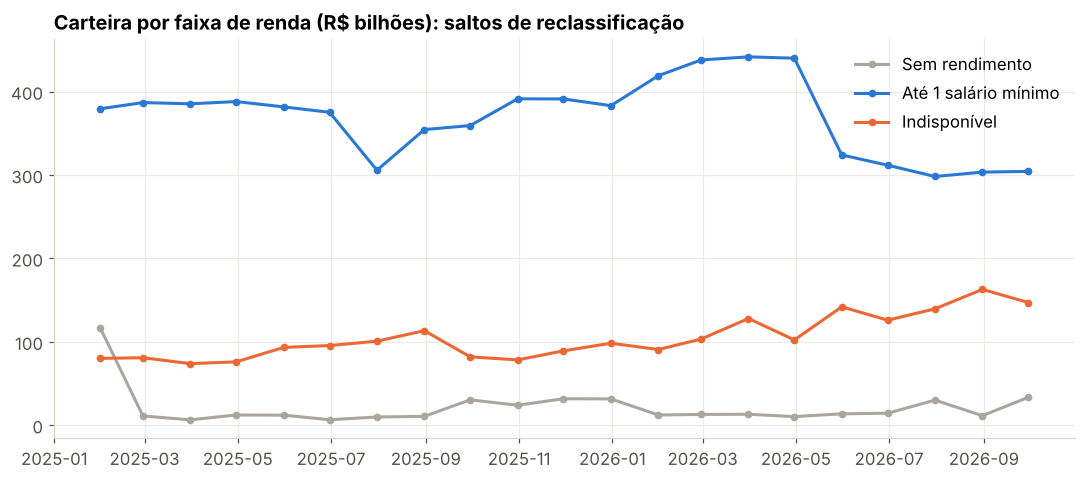

In [10]:
renda = q("SELECT mes, renda, SUM(carteira_ativa)/1e9 bi FROM pf GROUP BY ALL").pivot(
    index="mes", columns="renda", values="bi")[["Sem rendimento", "Até 1 salário mínimo", "Indisponível"]]
fig, ax = plt.subplots()
for col, cor in zip(renda.columns, [CINZA, AZUL, "#eb6834"]):
    ax.plot(renda.index, renda[col], marker="o", ms=4, lw=2, color=cor, label=col)
ax.set_title("Carteira por faixa de renda (R$ bilhões): saltos de reclassificação")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

Em fevereiro/2025 a faixa "Sem rendimento" cai de R$ 117 bi para R$ 11 bi, e em maio/2026 "Até 1 SM"
perde R$ 116 bi num mês, sem nenhum evento econômico que explique. São mudanças de classificação
na fonte. **Decisão:** renda é analisada **dentro de cada mês** (comparação entre faixas), nunca como
tendência ao longo do tempo. As categorias "Sem rendimento" e "Indisponível" aparecem separadas
nos gráficos.

### 5.3 Crédito rural

O crédito rural a pessoas físicas é crédito à **produção** (produtor rural pessoa física), não ao
consumo das famílias. Como veremos na EDA, ele explica uma parte grande da alta do período e
concentra-se em estados do agronegócio. **Decisão:** a análise principal usa o escopo
**"Consumo e habitação"** (sem rural e sem legado). O rural aparece como recorte próprio.

## 6. Validação contra as séries oficiais do Banco Central

In [11]:
sgs = t.ler_sgs(RAIZ / "dados" / "sgs.parquet", ate=MES_FIM)
consumo = q("""SELECT mes, 100 * SUM(carteira_inadimplencia) / SUM(carteira_ativa) taxa
               FROM pf WHERE grupo_produto NOT IN ('Rural', 'Cartão: saldo não migrado (legado)')
               GROUP BY 1 ORDER BY 1""").set_index("mes")
consumo.index = pd.to_datetime(consumo.index)
val = consumo.join(sgs["inadimplencia_credito_livre_pf"])
print(f"Correlação entre a taxa calculada (consumo) e a série oficial 21112: "
      f"{val.corr().iloc[0, 1]:.3f}")
val.iloc[[0, 6, 12, -1]]

Correlação entre a taxa calculada (consumo) e a série oficial 21112: 0.946


,taxa,inadimplencia_credito_livre_pf
mes,,
2025-01-31,3.30,5.74
2025-07-31,3.71,6.73
2026-01-31,4.03,7.17
2026-09-30,4.49,8.09


A taxa calculada no SCR.data acompanha a série oficial de inadimplência do crédito livre
(correlação acima de 0,94), mas em nível mais baixo. Isso é esperado: o escopo de consumo e habitação
inclui o **financiamento imobiliário**, crédito **direcionado** (com regras do governo) que é enorme e
quase não atrasa. O crédito livre, que a série 21112 mede, reúne cartão, cheque especial, crédito
pessoal (inclusive consignado) e veículos. A célula abaixo recalcula no SCR.data só o crédito livre,
usando a coluna `origem` ("sem destinação específica" = livre).
Os números de endividamento (29037) e comprometimento de renda (29034) chegaram a
50,1% e 29,0% em agosto/2026, os mesmos divulgados pelo Banco Central à imprensa.

In [12]:
livre = bruto.assign(livre=bruto.origem.astype(str).eq("Sem destinação específica"))
livre = (livre[livre.livre].groupby("data_base")[["carteira_inadimplencia", "carteira_ativa"]].sum())
livre = (100 * livre.carteira_inadimplencia / livre.carteira_ativa).rename("scr_so_credito_livre")
livre.index = pd.to_datetime(livre.index)
comp = pd.concat([livre, sgs["inadimplencia_credito_livre_pf"]], axis=1, sort=True).loc[livre.index]
dif = comp.iloc[:, 0] - comp.iloc[:, 1]
print(f"Diferença média (absoluta): {dif.abs().mean():.2f} p.p. · maior diferença: {dif.abs().max():.2f} p.p.")
print(f"Correlação das variações mensais: {comp.iloc[:, 0].diff().corr(comp.iloc[:, 1].diff()):.2f}")
comp.assign(diferenca_pp=dif).iloc[[0, 6, 8, 9, 12, -1]]

Diferença média (absoluta): 0.25 p.p. · maior diferença: 0.57 p.p.
Correlação das variações mensais: 0.83


,scr_so_credito_livre,inadimplencia_credito_livre_pf,diferenca_pp
data_base,,,
2025-01-31,5.66,5.74,-0.08
2025-07-31,6.69,6.73,-0.04
2025-09-30,6.96,6.89,0.07
2025-10-31,7.14,6.86,0.28
2026-01-31,7.49,7.17,0.32
2026-09-30,8.60,8.09,0.51


Recalculado só com o crédito livre, o SCR.data acompanha a série oficial: as duas praticamente
coincidem até set/2025 (diferença de no máximo 0,11 p.p.) e a distância média no período é de
0,25 p.p. A partir de out/2025, o cálculo passa a ficar até ~0,5 p.p. acima, e a causa não aparece
nos dados abertos (o saldo legado de cartão, que seria um candidato, cresce de forma contínua desde
jan/2025, sem salto em outubro).

Note que a correlação **no nível** (acima de 0,94) não serve como prova, pelo mesmo motivo discutido
na EDA para os juros: séries com tendência sempre parecem correlacionadas. O teste que importa é o
das **variações mensais**, que têm correlação de 0,83.

**Conclusão da preparação:** os dados são consistentes e confiáveis para a análise, com três
cuidados documentados: saldo legado de cartão à parte, renda só em corte transversal e crédito
rural em recorte próprio.